# Airline Passengers Forecast



            passengers
date                  
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
Rows: 144


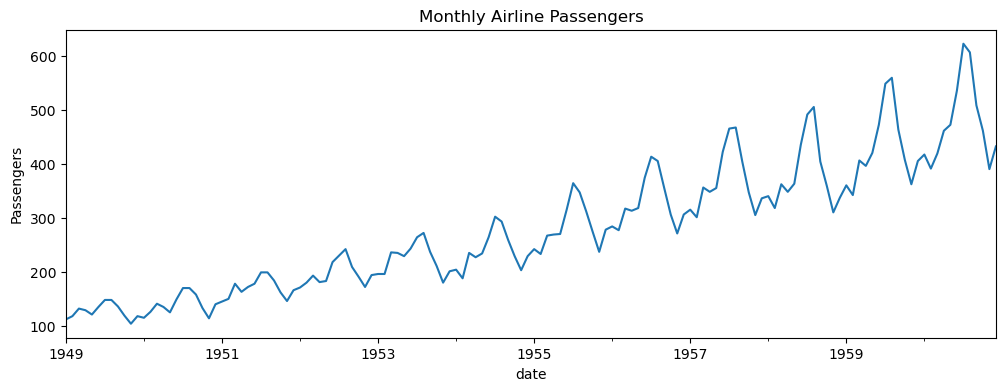

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
df = pd.read_csv(url)
df.columns = ['date', 'passengers']
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')

print(df.head())
print('Rows:', len(df))

df['passengers'].plot(figsize=(12, 4), title='Monthly Airline Passengers')
plt.ylabel('Passengers')
plt.show()


In [2]:
train = df.iloc[:-12].copy()
test = df.iloc[-12:].copy()

print('Training months:', len(train))
print('Test months:', len(test))


Training months: 132
Test months: 12


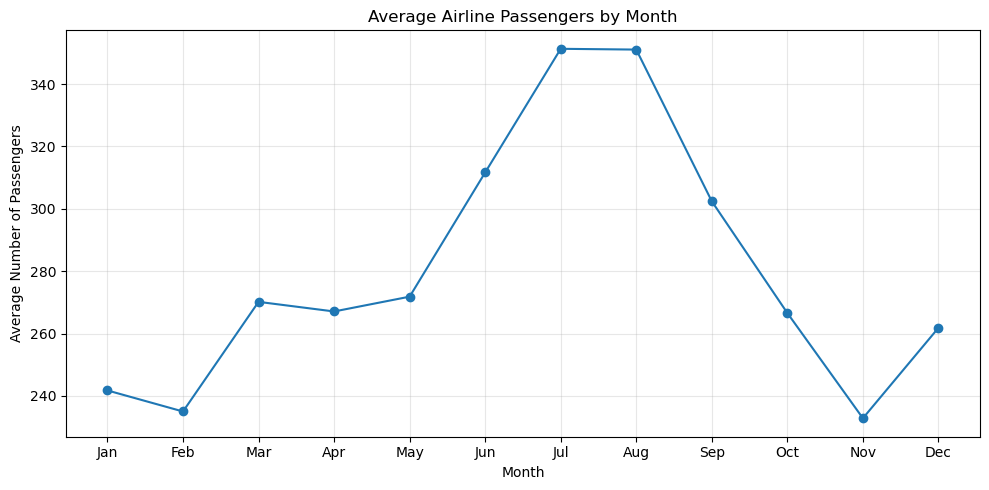

In [5]:
monthly_avg = df.groupby(df.index.month)["passengers"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average Airline Passengers by Month")
plt.xlabel("Month")
plt.ylabel("Average Number of Passengers")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Naive Forecast
naive_forecast = pd.Series(
    train['passengers'].iloc[-1],
    index=test.index
)

# 2. Holt-Winters Forecast
holt_model = ExponentialSmoothing(
    train['passengers'],
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()

holt_forecast = holt_model.forecast(len(test))
holt_forecast.index = test.index

# 3. Compare Actual and Predicted Values
forecasts = pd.DataFrame({
    'Actual': test['passengers'],
    'Naive': naive_forecast,
    'Holt-Winters': holt_forecast
})

forecasts.round(1)


C:\Users\geetb\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,Actual,Naive,Holt-Winters
date,,,
1960-01-01,417,405,415.5
1960-02-01,391,405,397.1
1960-03-01,419,405,457.5
1960-04-01,461,405,445.4
1960-05-01,472,405,466.2
1960-06-01,535,405,520.7
1960-07-01,622,405,592.4
1960-08-01,606,405,598.8
1960-09-01,508,405,498.8


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for model in ['Naive', 'Holt-Winters']:
    mae = mean_absolute_error(
        forecasts['Actual'], forecasts[model]
    )
    rmse = np.sqrt(mean_squared_error(
        forecasts['Actual'], forecasts[model]
    ))

    print(f"{model}:")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print()


Naive:
MAE: 76.00
RMSE: 102.98

Holt-Winters:
MAE: 13.38
RMSE: 16.98



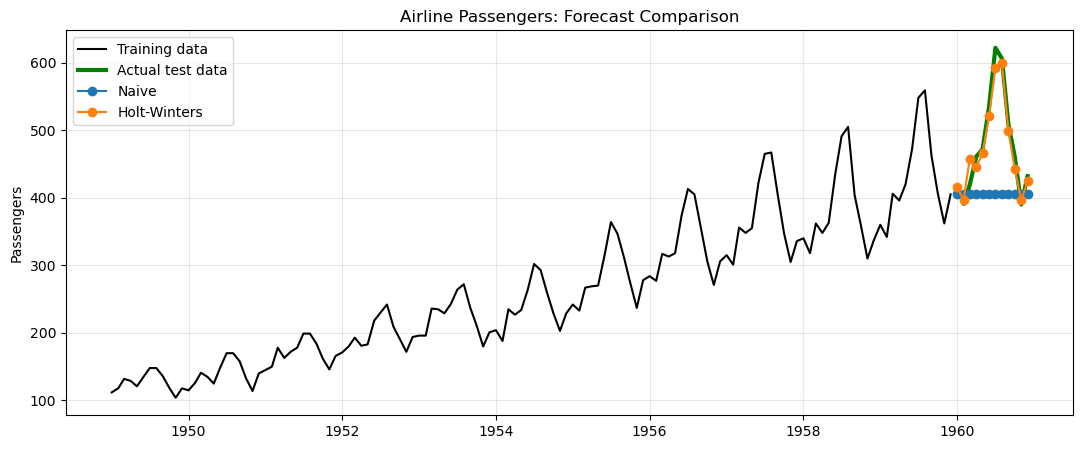

In [13]:
plt.figure(figsize=(13, 5))
plt.plot(train.index, train['passengers'], label='Training data', color='black')
plt.plot(test.index, test['passengers'], label='Actual test data', color='green', linewidth=3)
for method in ['Naive', 'Holt-Winters']:
    plt.plot(test.index, forecasts[method], marker='o', label=method)
plt.title('Airline Passengers: Forecast Comparison')
plt.ylabel('Passengers')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
